# Exploratory analysis of the Solomon instances

**What makes each family hard?** This notebook uses only the *input data* of the 56 Solomon instances (Solomon, 1987) — no solver results and no reference routes — and answers four questions:

1. How are customers distributed in the plane (clustered, random or mixed)?
2. How wide are the time windows relative to the horizon?
3. Is the fleet set by capacity or by time windows?
4. What share of customer pairs can actually be chained in one route?

The only exception to the inputs-only rule is the SINTEF reference vehicle count, which appears solely in the fleet-bounds section.

## 1. Environment setup

In this section the instances and the SINTEF vehicle table (used only in section 4) are loaded. The table shows the quantities read.

In [1]:
LANG = "en"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import eda, io, paths, viz_eda
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
instances = io.read_archive(P["sintef_zip"])
sintef = io.read_references(P["sintef_bks"])

display(eda.localize_columns(eda.family_summary(instances), LANG))

,Family,No. of instances,No. of customers,Fleet limit (K),Capacity (Q),Horizon,Service time,Mean total demand
0,C1,9,100,25,200,1236,90.0,1810.0
1,C2,8,100,25,700,3390,90.0,1810.0
2,R1,12,100,25,200,230,10.0,1458.0
3,R2,11,100,25,1000,1000,10.0,1458.0
4,RC1,8,100,25,200,240,10.0,1724.0
5,RC2,8,100,25,1000,960,10.0,1724.0


**Insight.** The 56 instances were loaded and the table shows the six families: capacities from 200 to 1000, horizons from 230 to 3390 and service time of 90 (C) or 10 (R and RC). It is observed that horizon and service time vary by orders of magnitude between families; the following analyses therefore use measures relative to the horizon whenever possible. **Next decision:** inspect the customer geography.

## 2. Customer geography

**Question:** how are customers distributed in the plane and how do time windows vary over space? **What the chart shows:** one map per instance (C101, C201, R101, R201, RC101, RC201); each point is a customer coloured by the start of its time window **divided by the instance horizon**, on the same 0 to 1 scale in every panel (the colour bar applies to all of them), and the red square is the depot.

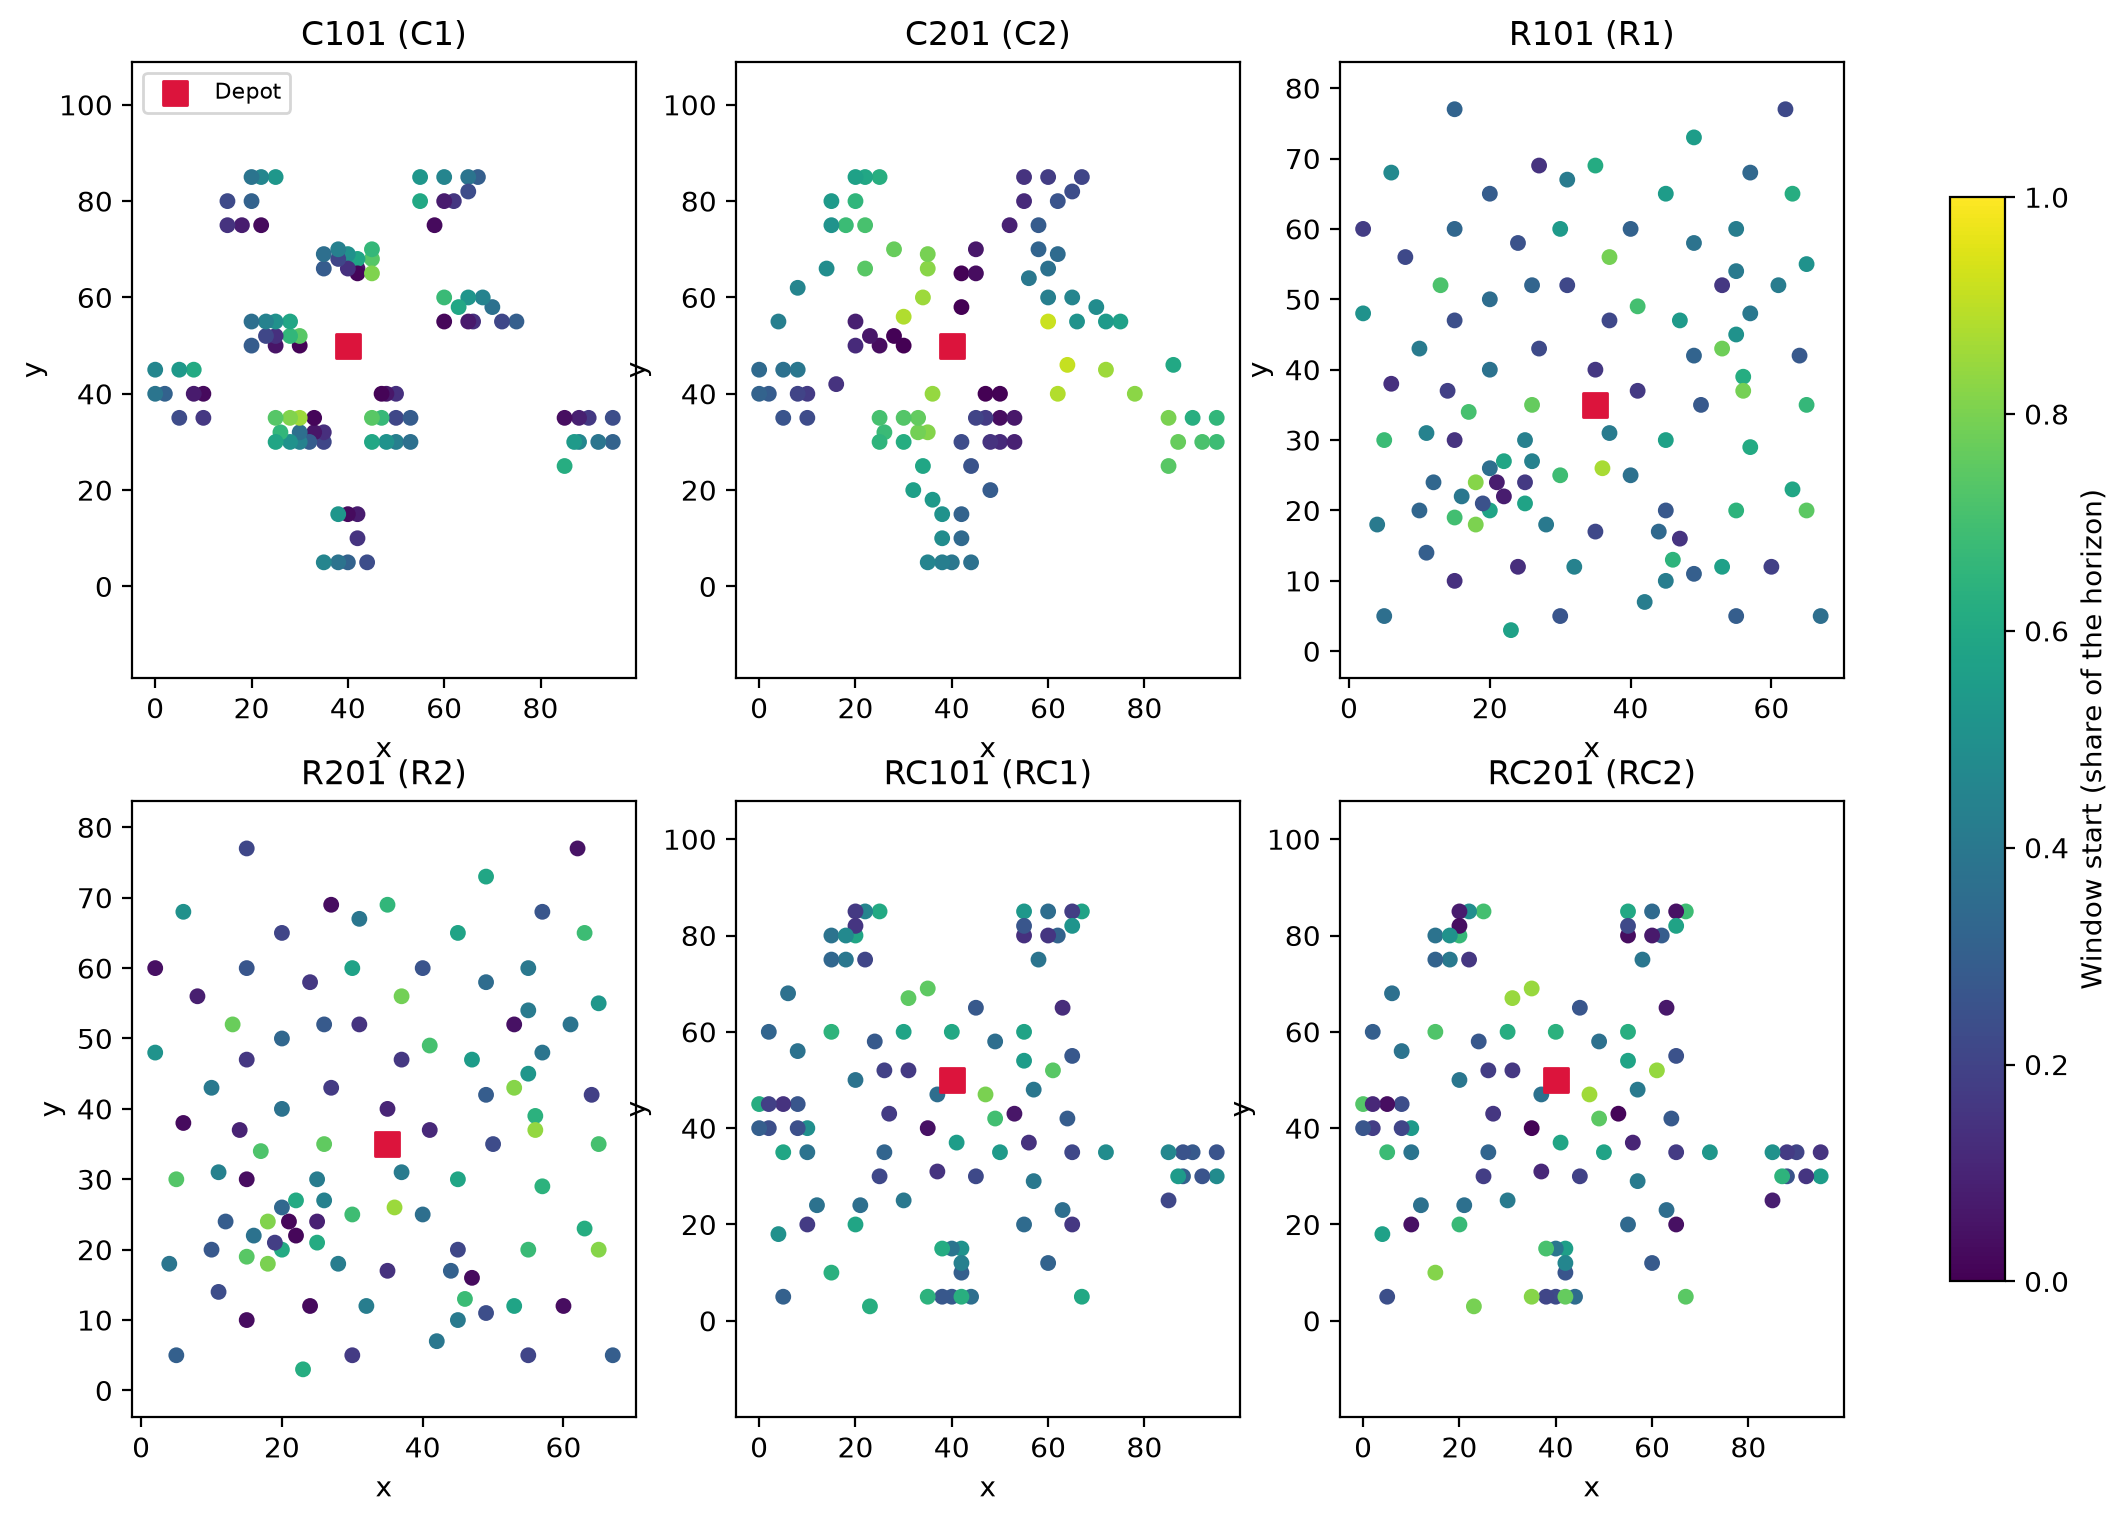

In [2]:
viz_eda.plot_family_layouts(instances, ["C101", "C201", "R101", "R201", "RC101", "RC201"], LANG)
plt.show()

**Insight.** In C101 and C201 the customers form compact clusters around the depot; in R101 and R201 they are scattered roughly uniformly; in RC101 and RC201 clusters and isolated points coexist. With the common 0 to 1 scale, the panels are comparable: in series 2 (C201, R201, RC201) there are more customers in teal and green tones (window start at a larger fraction of the horizon) than in series 1 (C101, R101, RC101), where violet and blue tones dominate; this is a visual reading, not quantified here (section 3 measures the width, not the start, of the windows). Visually, within the C clusters neighbouring customers tend to have window starts of similar colours, whereas in R no spatial pattern is perceived in the colours. The maps of R101 and R201 (and of RC101 and RC201) have the same positions; only the colour changes, since the window starts differ. **Limitations:** the reading is qualitative and covers 6 of the 56 instances; the colour is the window start divided by the horizon, on the same 0 to 1 scale in the six panels; in earlier versions of this notebook, the scale of each panel ran from 0 to the horizon of its own instance and the colour bar reflected only the last panel, which prevented comparing series (corrected on 2026-11-18). **Next decision:** quantify the window width.

## 3. Time windows

**Question:** how restrictive are the windows? **Metrics** (per instance, customers only): mean window width (due − ready), mean width divided by the horizon, share of customers whose window covers at least 90% of the horizon ("almost unconstrained") and mean service time divided by the horizon. The table summarises the means by family; the chart shows the distribution of the relative width across the instances of each family (box: quartiles; line: median).

,Family,Mean window width,Median window width,Width / horizon,Almost unconstrained customers,Service / horizon,Width / horizon (min.),Width / horizon (max.)
0,C1,320.991,318.444,0.260,0.104,0.073,0.049,0.690
1,C2,920.512,914.062,0.272,0.188,0.027,0.047,0.735
2,R1,86.959,82.833,0.378,0.027,0.043,0.043,0.667
3,R2,453.735,446.955,0.454,0.274,0.010,0.116,0.783
4,RC1,85.429,80.750,0.356,0.014,0.042,0.125,0.644
5,RC2,369.756,354.750,0.385,0.188,0.010,0.125,0.747


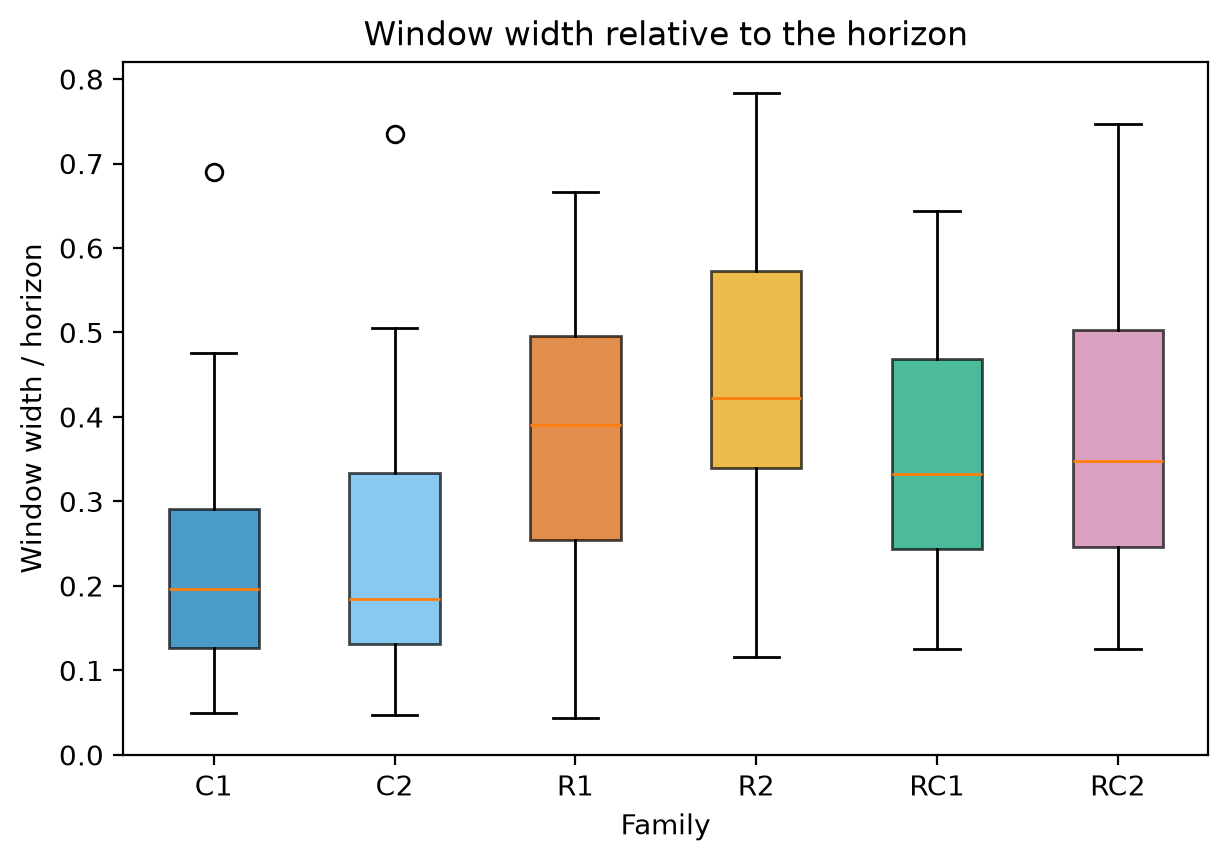

In [3]:
window = eda.window_stats(instances)
display(eda.localize_columns(eda.window_summary(window), LANG))

viz_eda.plot_window_widths(window, LANG)
plt.show()

**Insight.** In absolute terms, mean windows are much wider in series 2 (C2: 920.5 against 321.0 in C1; R2: 453.7 against 87.0 in R1; RC2: 369.8 against 85.4 in RC1). Relative to the horizon, however, the means are close (C1: 0.260; C2: 0.272; R1: 0.378; R2: 0.454; RC1: 0.356; RC2: 0.385). What separates the series is the share of almost unconstrained customers (window of at least 90% of the horizon): 2.7% in R1 and 1.4% in RC1, against 27.4% in R2 and 18.8% in RC2 (C1: 10.4%; C2: 18.8%). Service time weighs more in series 1 (4.2% to 7.3% of the horizon) than in series 2 (1.0% to 2.7%). The internal variation is large: the relative width ranges from 0.043 to 0.667 in R1 and from 0.116 to 0.783 in R2, so the family mean does not describe each instance. **Limitation:** the mean width does not reveal how windows overlap in time. **Next decision:** compare two instances of different series.

**Question:** how does the difference between series show up instance by instance? **What the chart shows:** for R101 (series 1) and R201 (series 2), one horizontal bar per customer, from window start to window end, sorted by start; the horizontal axis runs from 0 to the instance horizon.

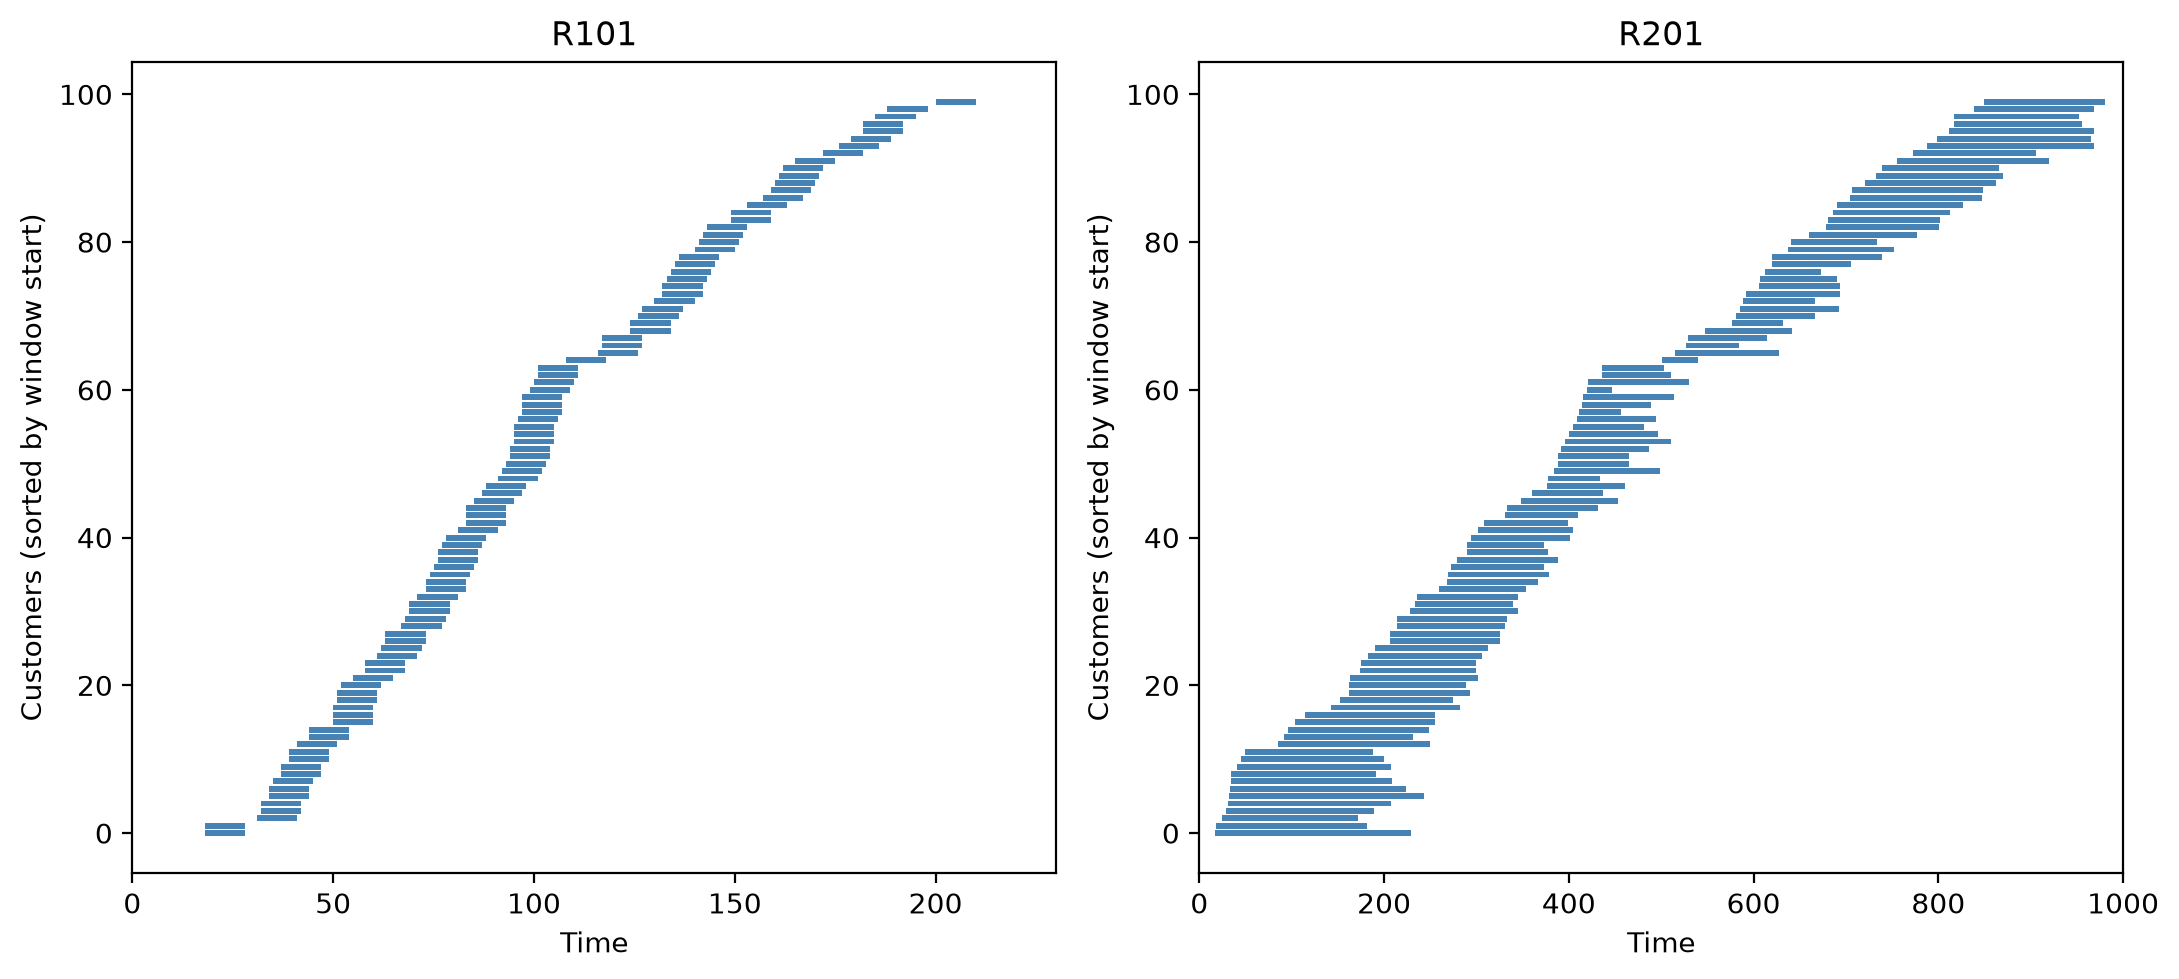

In [4]:
viz_eda.plot_window_comparison(instances, ["R101", "R201"], LANG)
plt.show()

**Insight.** In R101 the bars are short relative to the horizon (0 to 230) and few overlap at any given instant, so each customer can only be served within a narrow band; in R201 the bars are longer relative to the axis (0 to 1000) and many overlap. This is consistent with the minimum relative widths in the previous table (0.043 in R1 and 0.116 in R2), but these are only two instances out of the 23 R instances. **Limitation:** the chart shows the temporal structure, not the effect on routes. **Next decision:** relate the windows to the required fleet.

## 4. Demand and capacity

**Question:** is the fleet set by capacity or by time windows? **Metric:** the capacity lower bound, ⌈total demand / capacity⌉ (Toth & Vigo, 2014), is the smallest possible number of vehicles ignoring windows. It is compared with the number of vehicles in the SINTEF reference (SINTEF, 2008): if they are equal, capacity is the binding constraint; if the reference is larger, the windows (or their combination with capacity) require additional vehicles. The table summarises by family; the chart shows each instance (points slightly shifted by family so they do not overlap) and the equality diagonal.

,Family,No. of instances,Capacity lower bound,SINTEF vehicles,SINTEF vehicles (min.),SINTEF vehicles (max.),SINTEF / bound ratio,No. capacity-bound
0,C1,9,10.0,10.00,10,10,1.00,9
1,C2,8,3.0,3.00,3,3,1.00,8
2,R1,12,8.0,11.92,9,19,1.49,0
3,R2,11,2.0,2.73,2,4,1.36,4
4,RC1,8,9.0,11.50,10,14,1.28,0
5,RC2,8,2.0,3.25,3,4,1.62,0


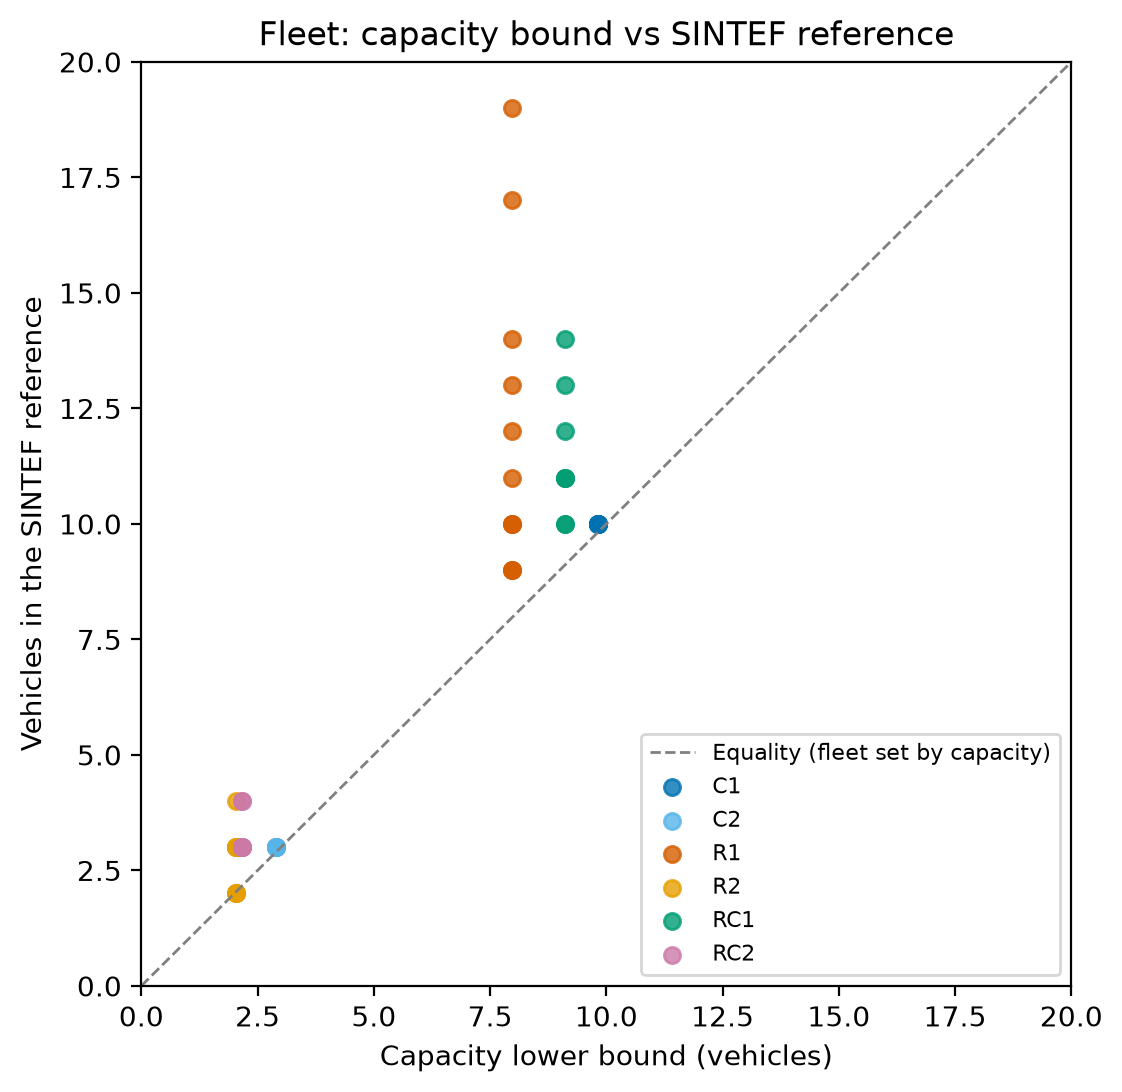

In [5]:
fleet = eda.fleet_bounds(instances, sintef)
display(eda.localize_columns(eda.fleet_summary(fleet), LANG))

viz_eda.plot_fleet_bounds(fleet, LANG)
plt.show()

**Insight.** In the C families the SINTEF reference fleet coincides with the capacity bound on every instance (9 of 9 in C1, with 10 vehicles; 8 of 8 in C2, with 3 vehicles), that is, capacity is the binding constraint. In the other families the reference exceeds the bound: R1 uses 11.92 vehicles on average against 8.0 (ratio 1.49; from 9 to 19 vehicles), RC1 11.50 against 9.0 (ratio 1.28), R2 2.73 against 2.0 (ratio 1.36; coincidence in 4 of 11 instances) and RC2 3.25 against 2.0 (ratio 1.62; no coincidence). In these families, time windows, alone or combined with capacity, require additional vehicles. **Limitations:** the capacity bound ignores routing and is loose by construction; and the reference is the best known solution, not a proven optimum, so the gap to the bound is an indicator, not an exact measure of the effect of windows. **Next decision:** measure temporal compatibility between customers.

## 5. Temporal compatibility

**Question:** what share of customer pairs can be chained? **Metric:** for each ordered pair of customers (i, j), i ≠ j, j can be served right after i if max(ready_i, d₀ᵢ) + service_i + dᵢⱼ ≤ due_j (service starts at the maximum of arrival and window opening, with hard windows; Toth & Vigo, 2014), using exact distances and with i served as early as possible from the depot. The temporal compatibility density, defined in this project, is the share of compatible pairs. It is a measure of instance structure: the lower the density, the fewer route combinations exist. The table summarises by family (mean, minimum and maximum); the chart shows each instance and the median of each family.

,Family,Compatibility density,Minimum density,Maximum density
0,C1,0.640,0.435,0.942
1,C2,0.692,0.507,0.969
2,R1,0.693,0.306,0.991
3,R2,0.850,0.577,0.989
4,RC1,0.648,0.347,0.919
5,RC2,0.811,0.577,0.999


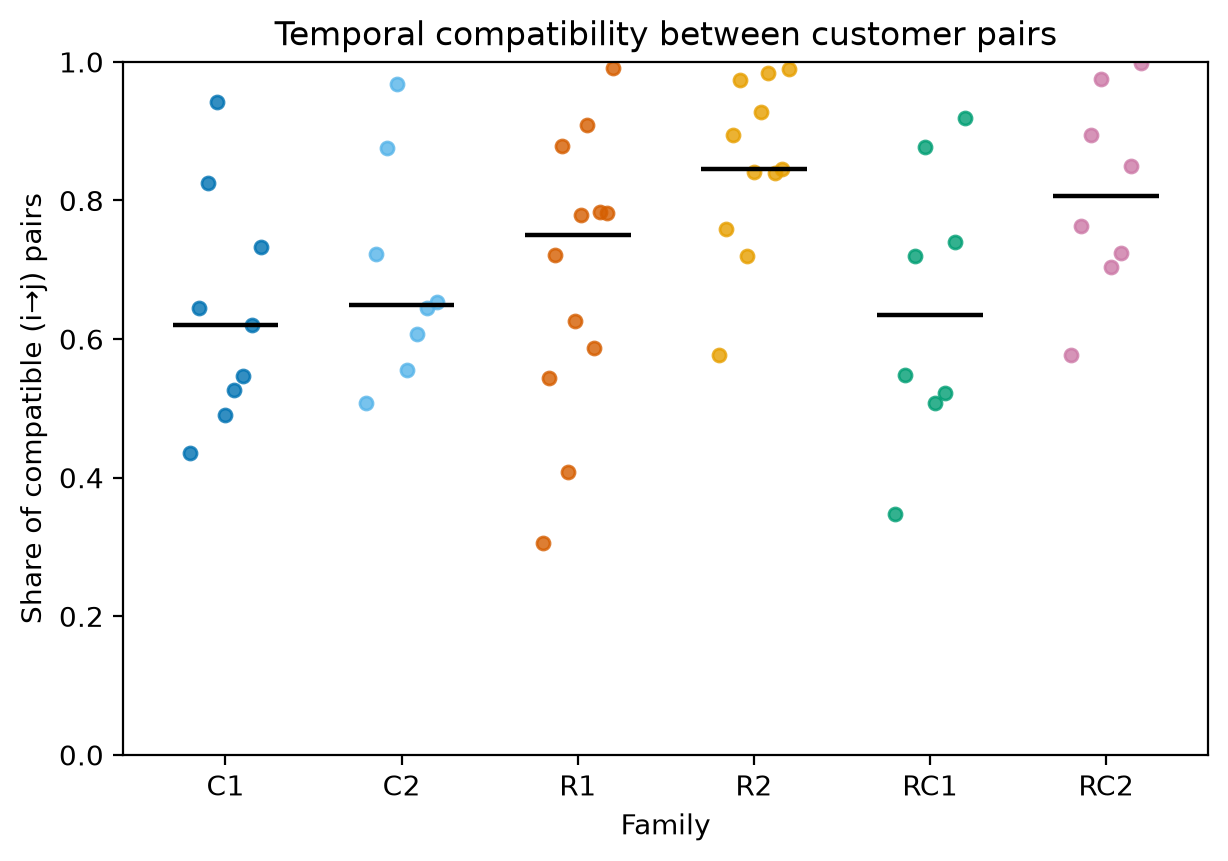

In [6]:
density = eda.compatibility_by_instance(instances)
display(eda.localize_columns(eda.compatibility_summary(density), LANG))

viz_eda.plot_compatibility(density, LANG)
plt.show()

**Insight.** Mean compatibility density is highest in the series-2 families of R and RC (R2: 0.850; RC2: 0.811) than in the others (C1: 0.640; C2: 0.692; R1: 0.693; RC1: 0.648). Within each family the variation is wide (for example, from 0.306 to 0.991 in R1 and from 0.347 to 0.919 in RC1), comparable to the difference between families; the family therefore describes only part of the structure of each instance. An association of this internal variation with window width is plausible but was not tested here. **Limitations:** the measure considers only consecutive pairs, without capacity or return to the depot, and does not capture longer chains; and service time differs widely between families (90 in C, 10 in R and RC), which mixes effects of service and windows. **Next decision:** gather the indicators by family.

## 6. Synthesis by family

**Question:** which input indicators distinguish the families and what do they suggest for solver performance? The table gathers, per family, the mean relative window width, the share of almost unconstrained customers, the mean capacity lower bound, the mean SINTEF reference vehicles, the ratio between the two and the mean compatibility density.

In [7]:
synthesis = eda.synthesis_table(window, fleet, density)
display(eda.localize_columns(synthesis, LANG))

,Family,Width / horizon,Almost unconstrained customers,Capacity lower bound,SINTEF vehicles,SINTEF / bound ratio,Compatibility density
0,C1,0.260,0.104,10.0,10.000,1.000,0.640
1,C2,0.272,0.188,3.0,3.000,1.000,0.692
2,R1,0.378,0.027,8.0,11.917,1.490,0.693
3,R2,0.454,0.274,2.0,2.727,1.364,0.850
4,RC1,0.356,0.014,9.0,11.500,1.278,0.648
5,RC2,0.385,0.188,2.0,3.250,1.625,0.811


**Insight.** The indicators distinguish two groups. In the C families the ratio of the SINTEF fleet to the capacity bound is 1.000 (C1 and C2), with compatibility densities of 0.640 and 0.692. In the R and RC families the ratio ranges from 1.278 (RC1) to 1.625 (RC2), with densities from 0.648 to 0.850. No single indicator orders the families: R2 has the highest density (0.850) and the highest share of almost unconstrained customers (0.274), but a fleet ratio of 1.364, lower than that of R1 (1.490) and RC2 (1.625); the relation between windows and excess fleet is therefore not monotonic in these data. **Expectation for the solver (hypothesis, not proof):** in the C families the fleet target coincides with the capacity bound, and in the R and RC families there is slack between the bound and the reference, which makes fleet minimisation more demanding. This is consistent with the development grid (`reports/protocolo-grade-dev.md`), in which the frozen configuration matched the SINTEF fleet on the 4 C development instances but used at least 1 vehicle more on 9 of the 10 R and RC development instances (+1 on seven, +2 on R110, +3 on RC106; R201 matched the reference). **Limitations:** the observation comes from 14 development instances with one replicate per cell and was not confronted with the evaluation instances; correlation between input indicators and outcome is not causation. **Next decision:** run the baselines and the frozen configuration on the evaluation set, reporting Δ vehicles and distance gap in separate columns.

## 7. Next steps

- Present the verifier, the baselines and the development tournament already run (notebooks 03 and 04), then run the frozen configuration on the evaluation instances (notebook 05), always with independent double-precision verification.
- Report Δ vehicles and distance gap in separate columns, the latter only when the fleet equals that of the SINTEF reference.
- Treat business scenarios (flexible windows, priorities, perturbations) as a separate layer, with no comparison to the benchmark.

## References

- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research, 35*(2), 254–265.
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.